In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

In [2]:
rng = np.random.default_rng()

with np.load("data/mnist.npz") as data:
    x_train_images = data["x_train"]
    y_train = data["y_train"]
    x_test_images = data["x_test"]
    y_test = data["y_test"]

print(f"Выборка train: изображения {x_train_images.shape}, метки {y_train.shape}\n"
    f"Выборка test: изображения {x_test_images.shape}, метки {y_test.shape}\n"
    f"Форма одного изображения: {x_train_images[0].shape}")

Выборка train: изображения (60000, 28, 28), метки (60000,)
Выборка test: изображения (10000, 28, 28), метки (10000,)
Форма одного изображения: (28, 28)


In [3]:
def show_images(images, labels, rows, columns, predictions = None):
    fig, axes = plt.subplots(rows, columns, figsize = (2 * columns, 2 * rows))
    axes = np.array(axes).reshape(-1)
    images_count = min(len(images), len(axes))

    for i in range(images_count):
        axes[i].imshow(images[i], cmap = "gray")
        axes[i].axis("off")

        if predictions is None:
            axes[i].set_title(f"Label: {labels[i]}")
        else:
            if predictions[i] == labels[i]:
                color = "green" 
            else:
                color = "red"
                
            axes[i].set_title(f"True: {labels[i]}\nPred: {predictions[i]}", color = color)

    for i in range(images_count, len(axes)):
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

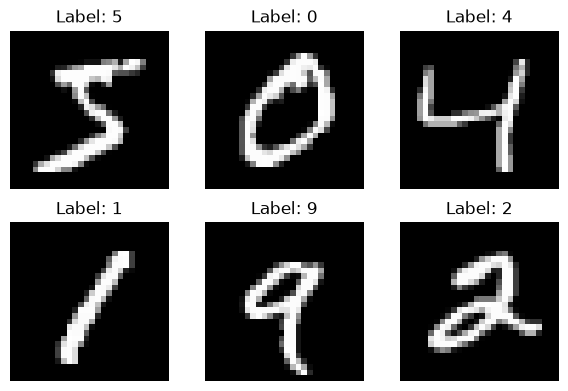

In [4]:
show_images(x_train_images[:6], y_train[:6], rows = 2, columns = 3)

In [5]:
x_train = x_train_images.reshape(len(x_train_images), -1).astype(np.float32) / 255.0
x_test = x_test_images.reshape(len(x_test_images), -1).astype(np.float32) / 255.0

def one_hot_encode(y, classes_count):
    one_hot = np.zeros((len(y), classes_count), dtype = np.float32)
    for i in range(len(y)):
        one_hot[i, y[i]] = 1.0
    return one_hot

def initialization(w_and_h, s, k, rng):
    W1 = rng.standard_normal((w_and_h, s), dtype=np.float32) * 0.05
    b1 = np.zeros(s, dtype = np.float32)
    W2 = rng.standard_normal((s, k), dtype=np.float32) * 0.05
    b2 = np.zeros(k, dtype = np.float32)
    return W1, b1, W2, b2

def relu(x):
    a1 = np.maximum(0, x)
    return a1

def softmax(values):
    shifted = values - values.max(axis = 1, keepdims = True)
    exp_values = np.exp(shifted)
    p = exp_values / exp_values.sum(axis = 1, keepdims = True)
    return p

def cross_entropy(probabilities, y):
    correct_class_probs = []

    for i in range(len(y)):
        correct_class = y[i]
        probability = probabilities[i, correct_class]
        correct_class_probs.append(probability)

    E = -np.log(np.clip(correct_class_probs, 1e-12, 1))
    E_mean = E.mean()
    return E_mean

def forward(X, W1, b1, W2, b2):
    z1 = X @ W1 + b1
    a1 = relu(z1)

    z2 = a1 @ W2 + b2
    p = softmax(z2)

    return z1, a1, p

def backward(X, y, Z1, A1, P, W2):
    Y = one_hot_encode(y, P.shape[1])
    G2 = (P - Y) / X.shape[0]

    dW2 = A1.T @ G2
    db2 = G2.sum(axis = 0)

    G1 = (G2 @ W2.T) * (Z1 > 0.0)
    dW1 = X.T @ G1
    db1 = G1.sum(axis = 0)

    return dW1, db1, dW2, db2

def predict(X, W1, b1, W2, b2, batch_size):
    predictions = []

    for start in range(0, len(X), batch_size):
        probabilities = forward(X[start:start + batch_size], W1, b1, W2, b2)[2]
        predictions.append(probabilities.argmax(axis = 1))
        
    return np.concatenate(predictions)

def classification_error(X, y, W1, b1, W2, b2):
    return np.mean(predict(X, W1, b1, W2, b2, 64) != y)

In [6]:
batch_size = 64
learning_rate = 0.1
epochs = 20

history = {"epoch_time": [], "train_error": []}

W1, b1, W2, b2 = initialization(w_and_h = 28 * 28, s = 300, k = 10, rng = rng)

for epoch in range(1, epochs + 1):
    started = perf_counter()
    permutation = rng.permutation(len(x_train))

    for start in range(0, len(x_train), batch_size):
        indices = permutation[start:start + batch_size]
        X_batch, y_batch = x_train[indices], y_train[indices]
        
        Z1, A1, probabilities = forward(X_batch, W1, b1, W2, b2)
        gradients = backward(X_batch, y_batch, Z1, A1, probabilities, W2)

        dW1, db1, dW2, db2 = gradients
        W1 -= learning_rate * dW1
        b1 -= learning_rate * db1
        W2 -= learning_rate * dW2
        b2 -= learning_rate * db2

    train_error = classification_error(x_train, y_train, W1, b1, W2, b2)
    time = perf_counter() - started
    history["epoch_time"].append(time)
    history["train_error"].append(train_error)

    print(f"{epoch} эпоха ({time:.2f} сек): ошибка на выборке train = {100 * train_error:.2f}%")

1 эпоха (6.81 сек): ошибка на выборке train = 6.41%
2 эпоха (4.69 сек): ошибка на выборке train = 4.70%
3 эпоха (3.64 сек): ошибка на выборке train = 3.28%
4 эпоха (3.15 сек): ошибка на выборке train = 2.81%
5 эпоха (6.28 сек): ошибка на выборке train = 2.38%
6 эпоха (2.87 сек): ошибка на выборке train = 2.14%
7 эпоха (2.45 сек): ошибка на выборке train = 1.81%
8 эпоха (3.76 сек): ошибка на выборке train = 1.46%
9 эпоха (2.81 сек): ошибка на выборке train = 1.24%
10 эпоха (2.71 сек): ошибка на выборке train = 1.11%
11 эпоха (2.98 сек): ошибка на выборке train = 0.99%
12 эпоха (3.21 сек): ошибка на выборке train = 0.87%
13 эпоха (11.07 сек): ошибка на выборке train = 0.98%
14 эпоха (4.50 сек): ошибка на выборке train = 0.65%
15 эпоха (2.53 сек): ошибка на выборке train = 0.56%
16 эпоха (3.13 сек): ошибка на выборке train = 0.49%
17 эпоха (2.79 сек): ошибка на выборке train = 0.41%
18 эпоха (2.55 сек): ошибка на выборке train = 0.32%
19 эпоха (2.70 сек): ошибка на выборке train = 0.27%
2

In [7]:
test_error = classification_error(x_test, y_test, W1, b1, W2, b2)
test_accuracy = 1 - test_error

print(f"Ошибка классификации на выборке test: {100 * test_error}%")
print(f"Точность на выборке test: {100 * test_accuracy}%")

Ошибка классификации на выборке test: 1.87%
Точность на выборке test: 98.13%


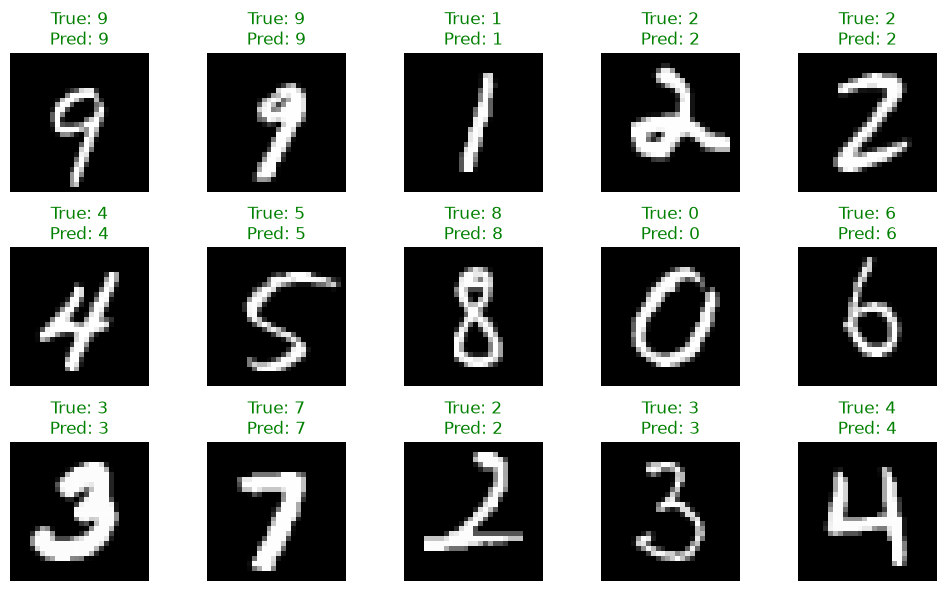

In [8]:
sample_indices = rng.choice(len(x_test), size = 15, replace = False)
sample_predictions = predict(x_test[sample_indices], W1, b1, W2, b2, 64)

show_images(x_test_images[sample_indices], y_test[sample_indices], rows = 3, columns = 5, predictions = sample_predictions)